<a href="https://colab.research.google.com/github/rachakondasaivarshini/GAN-PROGRAMS/blob/main/GAN_EXP11_PRELAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 167kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.12MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.6MB/s]


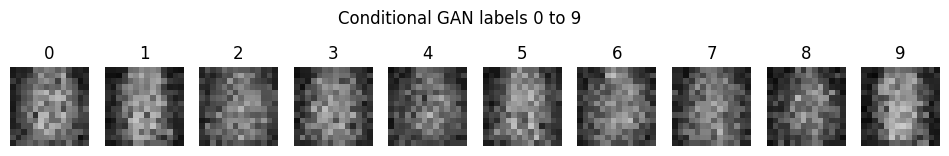

[0.7096473574638367,
 0.6988344788551331,
 0.6947717666625977,
 0.6940528154373169,
 0.68543541431427,
 0.6808069348335266,
 0.6764005422592163,
 0.6709498167037964,
 0.6694229245185852,
 0.6606929898262024,
 0.6547490358352661,
 0.6561046838760376,
 0.6421127915382385,
 0.6386146545410156,
 0.6348539590835571,
 0.6311002969741821,
 0.6294224262237549,
 0.6239519715309143,
 0.6135222315788269,
 0.6075018644332886,
 0.6086717247962952,
 0.6037798523902893,
 0.6065338253974915,
 0.6020923852920532,
 0.5992133617401123,
 0.5987342596054077,
 0.5912781953811646,
 0.5907593965530396,
 0.5795315504074097,
 0.584761381149292,
 0.5832536220550537,
 0.5765154957771301,
 0.581303060054779,
 0.5808874368667603,
 0.5793649554252625,
 0.5795673131942749,
 0.5809156894683838,
 0.5803126692771912,
 0.5734740495681763,
 0.5749783515930176,
 0.5851975679397583,
 0.574020266532898,
 0.5906541347503662,
 0.5800741910934448,
 0.5909338593482971,
 0.5870784521102905,
 0.5957765579223633,
 0.599102854728698

In [1]:

import torch
from torch import nn
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(7)
torch.set_num_threads(2)

device = "cuda" if torch.cuda.is_available() else "cpu"

transform = transforms.Compose([
    transforms.Resize((14, 14)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

data = datasets.FashionMNIST(
    "/content/data", download=True, transform=transform
)

loader = torch.utils.data.DataLoader(
    data, batch_size=64, shuffle=True, drop_last=True
)

def run(steps=300):
    extra = 10

    G = nn.Sequential(
        nn.Linear(32 + extra, 128),
        nn.ReLU(),
        nn.Linear(128, 196),
        nn.Tanh()
    ).to(device)

    D = nn.Sequential(
        nn.Linear(196 + extra, 128),
        nn.LeakyReLU(0.2),
        nn.Linear(128, 1)
    ).to(device)

    og = torch.optim.Adam(
        G.parameters(), lr=0.0002, betas=(0.5, 0.9)
    )

    od = torch.optim.Adam(
        D.parameters(), lr=0.0002, betas=(0.5, 0.9)
    )

    batches = iter(loader)
    history = []

    for step in range(steps):
        try:
            x, labels = next(batches)
        except StopIteration:
            batches = iter(loader)
            x, labels = next(batches)

        x = x.to(device).flatten(1)
        n = len(x)

        y = nn.functional.one_hot(
            labels.to(device), 10
        ).float()

        z = torch.randn(n, 32, device=device)
        fake = G(torch.cat([z, y], 1))

        real_score = D(torch.cat([x, y], 1))
        fake_score = D(torch.cat([fake.detach(), y], 1))

        ld = (
            nn.functional.softplus(-real_score).mean()
            + nn.functional.softplus(fake_score).mean()
        )

        od.zero_grad()
        ld.backward()
        od.step()

        score = D(torch.cat([fake, y], 1))
        lg = nn.functional.softplus(-score).mean()

        og.zero_grad()
        lg.backward()
        og.step()

        history.append(lg.item())

    with torch.no_grad():
        z = torch.randn(10, 32, device=device)
        z = torch.cat([z, torch.eye(10, device=device)], 1)

        images = G(z).cpu().reshape(10, 14, 14)

    fig, axes = plt.subplots(1, 10, figsize=(12, 2))

    for i, ax in enumerate(axes):
        ax.imshow((images[i] + 1)/2, cmap="gray",
                  vmin=0, vmax=1)
        ax.set_title(str(i))
        ax.axis("off")

    plt.suptitle("Conditional GAN labels 0 to 9")
    plt.show()

    return history

run()
